In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('Hospital_Inpatient_Discharges__SPARCS_De-Identified___2021_20231012 2.csv')

/var/folders/t0/tpz18mtn6dx0mqhzlp2q92tr0000gn/T/ipykernel_3116/1684402119.py:1: DtypeWarning: Columns (0: Length of Stay, 1: Birth Weight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Hospital_Inpatient_Discharges__SPARCS_De-Identified___2021_20231012 2.csv')


In [6]:
df.head()

,Hospital Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code - 3 digits,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Extreme,Medical,Medicare,Medicaid,NaN,NaN,Y,"320,922.43","60,241.34"
1,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,White,Not Span/Hispanic,...,Moderate,Minor,Medical,Private Health Insurance,NaN,NaN,NaN,Y,"61,665.22","9,180.69"
2,New York City,Bronx,7000006.0,1168.0,Montefiore Medical Center-Wakefield Hospital,18 to 29,104,F,Other Race,Spanish/Hispanic,...,Minor,Minor,Surgical,Medicaid,NaN,NaN,NaN,N,"42,705.34","11,366.5"
3,New York City,Bronx,7000006.0,3058.0,Montefiore Med Center - Jack D Weiler Hosp of ...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Major,Medical,Medicare,Medicaid,NaN,NaN,Y,"72,700.17","12,111.75"
4,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,Black/African American,Not Span/Hispanic,...,Moderate,Minor,Medical,Medicare,Medicaid,NaN,NaN,Y,"55,562.51","8,339.72"


In [7]:
df['Length of Stay'] = pd.to_numeric(df['Length of Stay'], errors='coerce')
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

In [8]:
los = df['Length of Stay'].dropna()

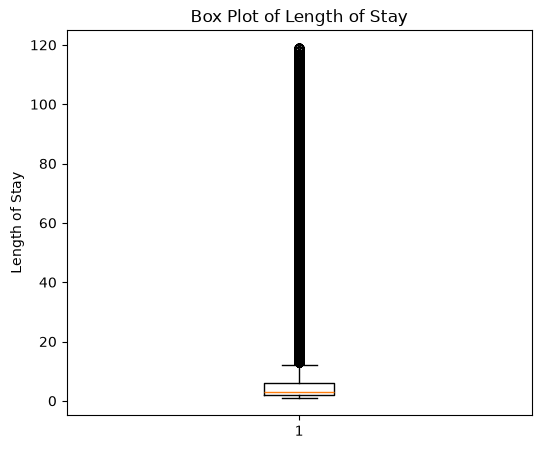

In [9]:
plt.figure(figsize=(6,5))
plt.boxplot(los.values)
plt.title('Box Plot of Length of Stay')
plt.ylabel('Length of Stay')
plt.show()

In [10]:
import seaborn as sns 

In [11]:
numeric_df = df.select_dtypes(include='number')

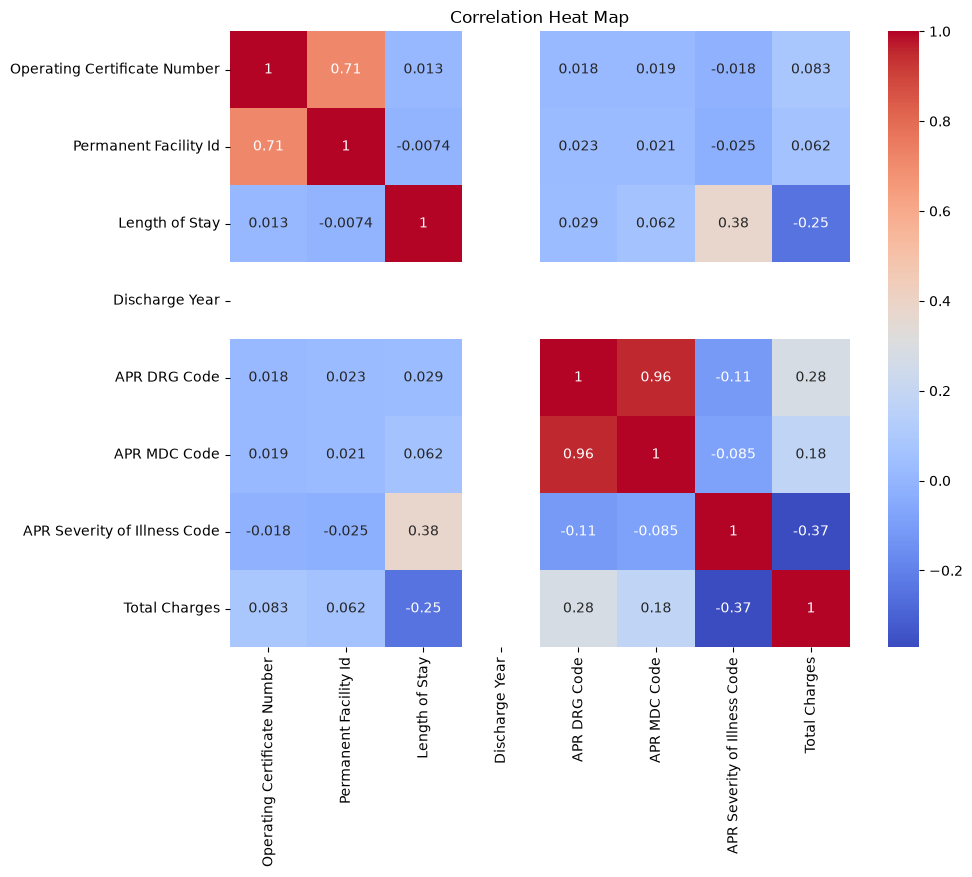

In [12]:
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.show()

In [13]:
numeric_df = df.select_dtypes(include='number')

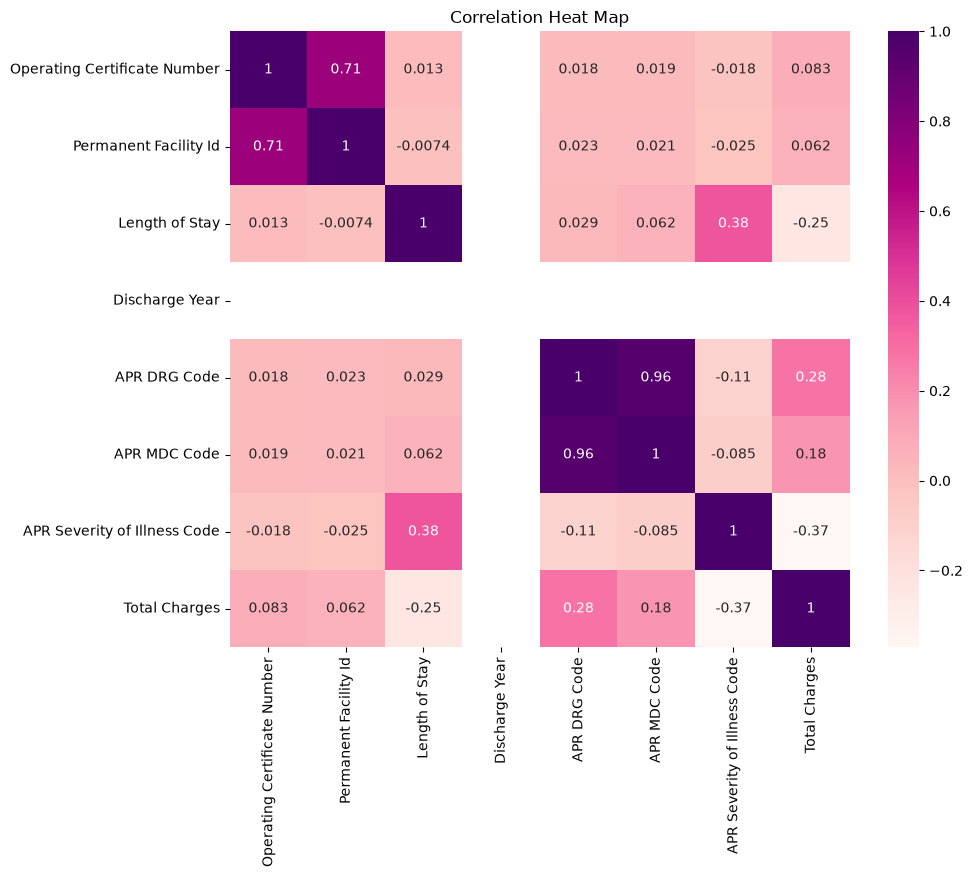

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='RdPu')
plt.title('Correlation Heat Map')
plt.show()

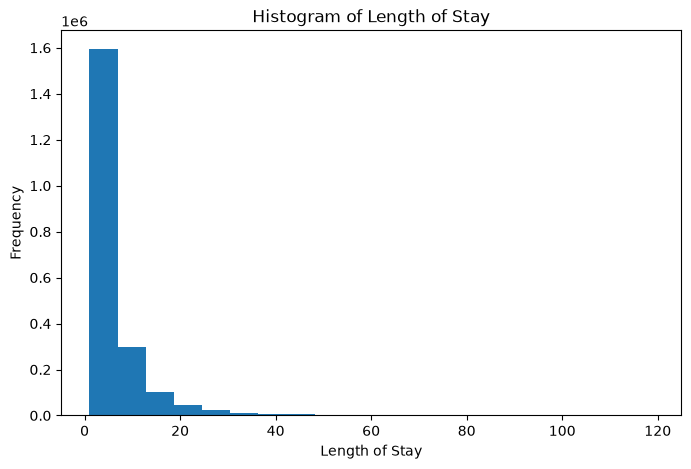

In [15]:
plt.figure(figsize=(8,5))
plt.hist(df['Length of Stay'].dropna(), bins=20)
plt.xlabel('Length of Stay')
plt.ylabel('Frequency')
plt.title('Histogram of Length of Stay')
plt.show()

In [16]:
def Desc_stat(ds, var):
    mean = ds[var].mean()
    median = ds[var].median()
    mode = ds[var].mode()
    std_dev = ds[var].std()
    variance = ds[var].var()
    minimum = ds[var].min()
    maximum = ds[var].max()
    skew = ds[var].skew()
    count = ds[var].count()

    Quart = [
        ds[var].quantile(0.25),
        ds[var].quantile(0.50),
        ds[var].quantile(0.75)
    ]

    summary = {
        "Count ": count,
        "Mean ": mean,
        "Median ": median,
        "Mode ": mode,
        "Std Dev ": std_dev,
        "Variance ": variance,
        "Minimum ": minimum,
        "Maximum ": maximum,
        "Q1 ": Quart[0],
        "Q2 ": Quart[1],
        "Q3 ": Quart[2],
        "Skewness ": skew
    }

    return summary

In [17]:
summary = Desc_stat(df, 'Length of Stay')
print(summary)

{'Count ': np.int64(2100027), 'Mean ': np.float64(5.657057266406575), 'Median ': np.float64(3.0), 'Mode ': 0    2.0
Name: Length of Stay, dtype: float64, 'Std Dev ': np.float64(7.82065553173315), 'Variance ': np.float64(61.162652946028324), 'Minimum ': np.float64(1.0), 'Maximum ': np.float64(119.0), 'Q1 ': np.float64(2.0), 'Q2 ': np.float64(3.0), 'Q3 ': np.float64(6.0), 'Skewness ': np.float64(4.992878286141345)}


In [27]:
summary = Desc_stat(df, 'Length of Stay')

print("Count =", summary["Count "])
print("Mean =", summary["Mean "])
print("Median =", summary["Median "])
print("Mode =", summary["Mode "][0])
print("Standard Deviation =", summary["Std Dev "])
print("Variance =", summary["Variance "])
print("Minimum =", summary["Minimum "])
print("Maximum =", summary["Maximum "])
print("Q1 =", summary["Q1 "])
print("Q2 =", summary["Q2 "])
print("Q3 =", summary["Q3 "])
print("Skewness =", summary["Skewness "])


KeyError: 'Count '